# ML Zoomcamp 2026 – Homework 2: Car Fuel Efficiency Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
df = pd.read_csv('car_fuel_efficiency_2026.csv')
cols = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']
df = df[cols]
df.shape

(10000, 5)

## EDA
Does `fuel_efficiency_mpg` have a long tail?

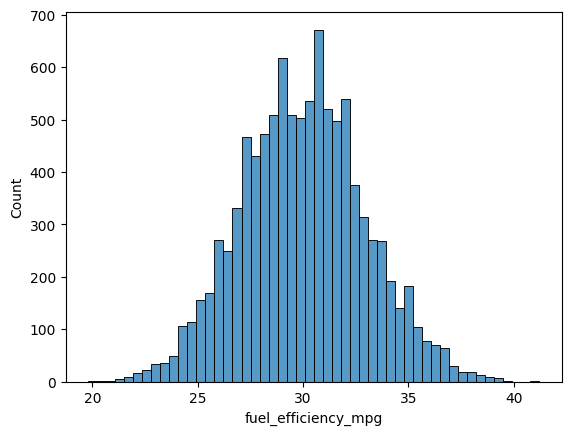

skew: 0.08080419601878173


In [2]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)
plt.show()
print('skew:', df.fuel_efficiency_mpg.skew())

No long tail – the distribution is roughly symmetric (skew ≈ 0.08).

## Question 1: column with missing values

In [3]:
df.isna().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

**Answer: `horsepower`**

## Question 2: median of `horsepower`

In [4]:
df.horsepower.median()

np.float64(254.0)

**Answer: 254**

## Split helper and linear regression

In [5]:
def split(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]
    return df_train, df_val, df_test


def train_linear_regression(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    w_full = np.linalg.inv(XTX).dot(X.T).dot(y)
    return w_full[0], w_full[1:]


def predict(X, w0, w):
    return w0 + X.dot(w)


def rmse(y, y_pred):
    return np.sqrt(((y - y_pred) ** 2).mean())


def prepare_X(d, fill):
    X = d.drop(columns='fuel_efficiency_mpg').fillna(fill).values
    y = d.fuel_efficiency_mpg.values
    return X, y

## Question 3: fill NAs with 0 vs. mean (mean from train only)

In [6]:
df_train, df_val, df_test = split(df, 42)

results = {}
for name, fill in [('0', 0), ('mean', df_train.horsepower.mean())]:
    X_train, y_train = prepare_X(df_train, fill)
    X_val, y_val = prepare_X(df_val, fill)
    w0, w = train_linear_regression(X_train, y_train)
    results[name] = round(rmse(y_val, predict(X_val, w0, w)), 3)
results

{'0': np.float64(2.205), 'mean': np.float64(2.202)}

**Answer: With mean** (2.202 vs 2.205)

## Question 4: regularization (NAs filled with 0)

In [7]:
X_train, y_train = prepare_X(df_train, 0)
X_val, y_val = prepare_X(df_val, 0)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression(X_train, y_train, r=r)
    print(r, round(rmse(y_val, predict(X_val, w0, w)), 4))

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


**Answer: r = 0**

## Question 5: effect of the seed

In [8]:
scores = []
for seed in range(10):
    tr, va, _ = split(df, seed)
    X_tr, y_tr = prepare_X(tr, 0)
    X_va, y_va = prepare_X(va, 0)
    w0, w = train_linear_regression(X_tr, y_tr)
    scores.append(rmse(y_va, predict(X_va, w0, w)))

print(scores)
round(np.std(scores), 3)

[np.float64(2.2392041430461465), np.float64(2.2021128210838907), np.float64(2.163419778753095), np.float64(2.2043588768539144), np.float64(2.2018800943312926), np.float64(2.2457851509084974), np.float64(2.269721207952404), np.float64(2.190794599933433), np.float64(2.2166112016864443), np.float64(2.207036592817851)]


np.float64(0.029)

**Answer: 0.029**

## Question 6: final model on test (seed 9, train+val, r=0.001)

In [9]:
df_train, df_val, df_test = split(df, 9)
df_full = pd.concat([df_train, df_val])

X_full, y_full = prepare_X(df_full, 0)
X_test, y_test = prepare_X(df_test, 0)

w0, w = train_linear_regression(X_full, y_full, r=0.001)
rmse(y_test, predict(X_test, w0, w))

np.float64(2.2358277471917636)

**Answer: 2.236**

## Summary
| Q | Answer |
|---|---|
| 1 | horsepower |
| 2 | 254 |
| 3 | With mean |
| 4 | 0 |
| 5 | 0.029 |
| 6 | 2.236 |